In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
df = pd.read_csv(url)

df.columns = ["date", "temperature"]
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["temperature"] = pd.to_numeric(df["temperature"], errors="coerce")

df = df.dropna(subset=["date", "temperature"])
df = df.drop_duplicates(subset=["date"])
df = df.sort_values("date")
df = df.set_index("date")

df = df.asfreq("D")
df["temperature"] = df["temperature"].interpolate(method="time")

print(df.head())
print("\nDataset shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())

            temperature
date                   
1981-01-01         20.7
1981-01-02         17.9
1981-01-03         18.8
1981-01-04         14.6
1981-01-05         15.8

Dataset shape: (3652, 1)

Missing values:
 temperature    0
dtype: int64


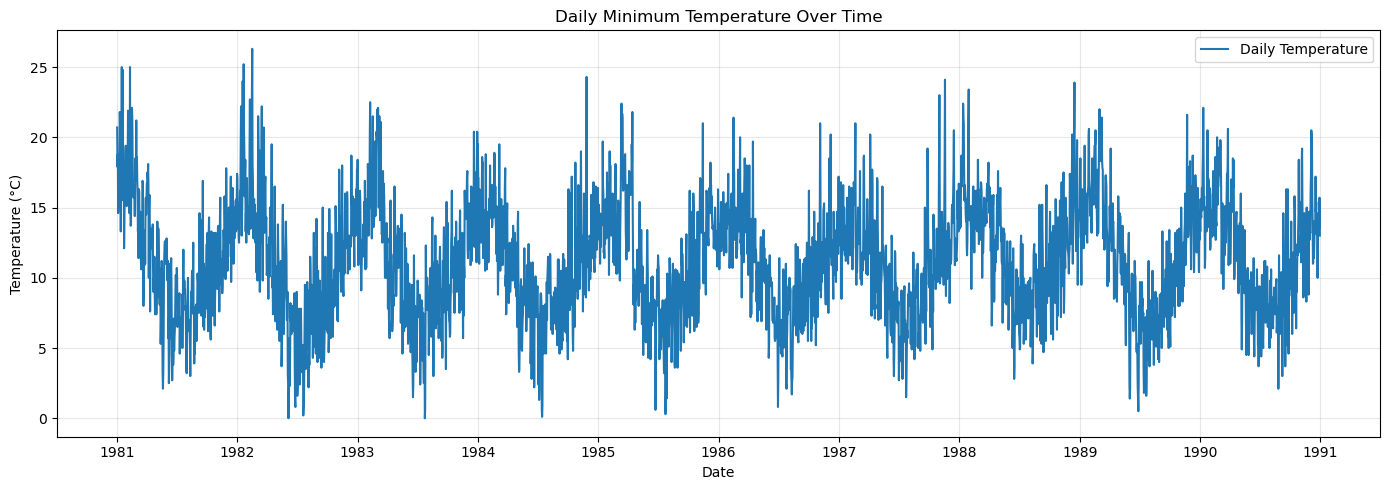

In [2]:
plt.figure(figsize=(14, 5))

plt.plot(df.index, df["temperature"], label="Daily Temperature")

plt.title("Daily Minimum Temperature Over Time")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [3]:
train = df.iloc[:-30].copy()
test = df.iloc[-30:].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Test period:", test.index.min(), "to", test.index.max())

Training rows: 3622
Testing rows: 30
Test period: 1990-12-02 00:00:00 to 1990-12-31 00:00:00


In [4]:
model = ExponentialSmoothing(
    train["temperature"],
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
)

fitted_model = model.fit(optimized=True)

# Predict the final 30 days
test_predictions = fitted_model.forecast(steps=len(test))

print("Test predictions:")
print(test_predictions.round(2))

Test predictions:
1990-12-02    13.06
1990-12-03    13.21
1990-12-04    13.29
1990-12-05    13.36
1990-12-06    13.21
1990-12-07    13.18
1990-12-08    13.15
1990-12-09    13.05
1990-12-10    13.20
1990-12-11    13.28
1990-12-12    13.35
1990-12-13    13.20
1990-12-14    13.17
1990-12-15    13.14
1990-12-16    13.04
1990-12-17    13.19
1990-12-18    13.27
1990-12-19    13.34
1990-12-20    13.19
1990-12-21    13.16
1990-12-22    13.12
1990-12-23    13.03
1990-12-24    13.18
1990-12-25    13.26
1990-12-26    13.33
1990-12-27    13.18
1990-12-28    13.15
1990-12-29    13.11
1990-12-30    13.02
1990-12-31    13.17
Freq: D, dtype: float64


In [5]:
mae = mean_absolute_error(
    test["temperature"],
    test_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        test["temperature"],
        test_predictions
    )
)

print("Model Evaluation")
print("----------------")
print(f"MAE: {mae:.2f} °C")
print(f"RMSE: {rmse:.2f} °C")

Model Evaluation
----------------
MAE: 1.92 °C
RMSE: 2.76 °C


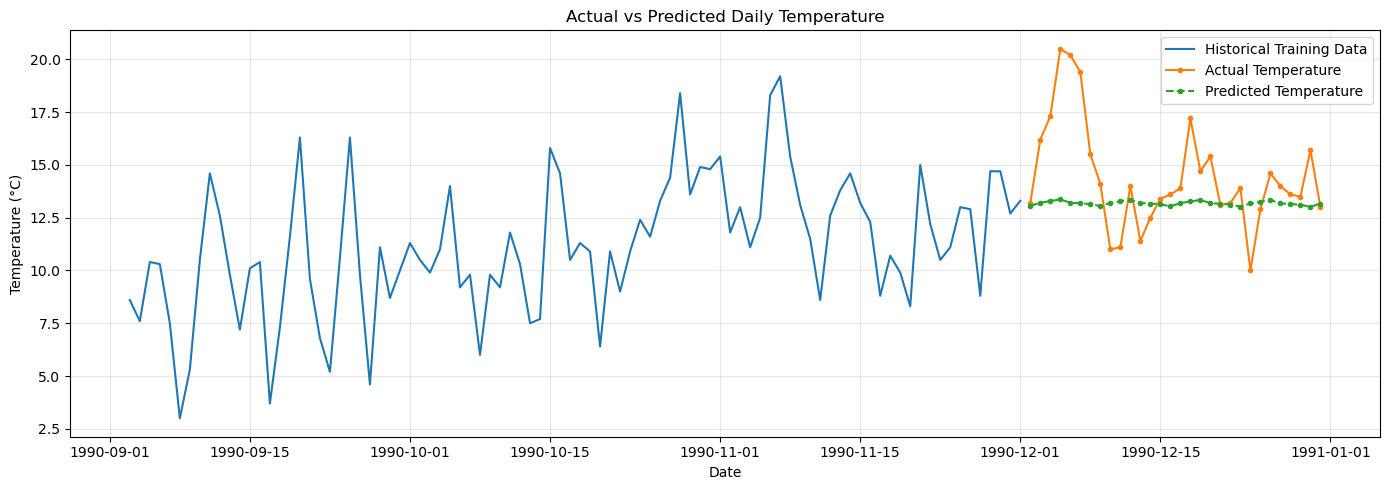

In [6]:
plt.figure(figsize=(14, 5))

plt.plot(
    train.index[-90:],
    train["temperature"].iloc[-90:],
    label="Historical Training Data"
)

# Actual test temperatures
plt.plot(
    test.index,
    test["temperature"],
    label="Actual Temperature",
    marker="o",
    markersize=3
)

# Predicted test temperatures
plt.plot(
    test_predictions.index,
    test_predictions,
    label="Predicted Temperature",
    linestyle="--",
    marker="o",
    markersize=3
)

plt.title("Actual vs Predicted Daily Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
final_model = ExponentialSmoothing(
    df["temperature"],
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit(optimized=True)

forecast = final_model.forecast(steps=30)

print("Forecast for the next 30 days:")
print(forecast.round(2))

Forecast for the next 30 days:
1991-01-01    13.97
1991-01-02    14.06
1991-01-03    13.90
1991-01-04    13.87
1991-01-05    13.83
1991-01-06    13.73
1991-01-07    13.87
1991-01-08    13.96
1991-01-09    14.05
1991-01-10    13.89
1991-01-11    13.86
1991-01-12    13.82
1991-01-13    13.73
1991-01-14    13.86
1991-01-15    13.96
1991-01-16    14.04
1991-01-17    13.88
1991-01-18    13.85
1991-01-19    13.81
1991-01-20    13.72
1991-01-21    13.85
1991-01-22    13.95
1991-01-23    14.03
1991-01-24    13.87
1991-01-25    13.84
1991-01-26    13.80
1991-01-27    13.71
1991-01-28    13.84
1991-01-29    13.94
1991-01-30    14.02
Freq: D, dtype: float64


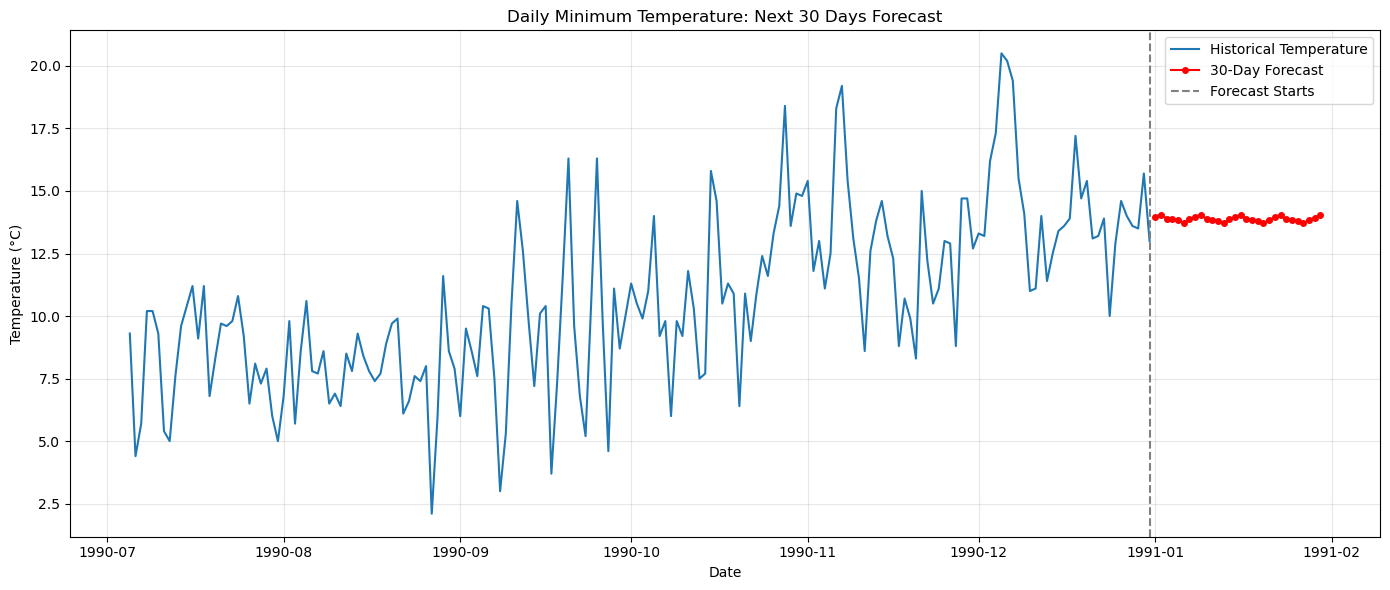

In [11]:
plt.figure(figsize=(14, 6))

# Recent 180 days of historical data
plt.plot(
    df.index[-180:],
    df["temperature"].iloc[-180:],
    label="Historical Temperature"
)

# Next 30 days
plt.plot(
    forecast.index,
    forecast,
    color="red",
    marker="o",
    markersize=4,
    label="30-Day Forecast"
)

plt.axvline(
    df.index[-1],
    color="gray",
    linestyle="--",
    label="Forecast Starts"
)

plt.title("Daily Minimum Temperature: Next 30 Days Forecast")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
forecast_df = forecast.rename(
    "forecast_temperature"
).to_frame()

forecast_df.index.name = "date"

forecast_df.to_csv("temperature_30_day_forecast.csv")

print("Forecast saved as temperature_30_day_forecast.csv")
print(forecast_df.head())

Forecast saved as temperature_30_day_forecast.csv
            forecast_temperature
date                            
1991-01-01             13.974046
1991-01-02             14.058789
1991-01-03             13.899014
1991-01-04             13.868255
1991-01-05             13.826820
